# Bab 2 - Konsep Dasar: Tipe Model dan Kosakata

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Bab 2 membangun kosakata dasar yang digunakan di sisa buku ini:

1. **Supervised vs. unsupervised learning:** supervised menggunakan data berlabel; unsupervised mencari struktur bawaan tanpa label.
2. **Model parametrik vs. non-parametrik:** model parametrik meringkas data ke dalam jumlah bobot yang tetap; model non-parametrik menyimpan data dan ukurannya bertambah seiring bertambahnya data.
3. **Alur predict-compare-learn:** tiga langkah yang dijalankan oleh setiap model supervised.

## Teori secara mendalam

### Supervised vs. unsupervised learning
* **Supervised:** data hadir dalam pasangan (input `x`, target `y`). Tujuan model adalah mempelajari fungsi `f(x) -> y` yang memprediksi target untuk input baru yang belum pernah dilihat.
* **Unsupervised:** kita hanya memiliki input `x` tanpa label. Tugas model adalah menemukan pola, kluster, atau struktur di dalam data (misalnya mengelompokkan pelanggan serupa).

### Parametrik vs. non-parametrik
* **Parametrik:** model memiliki jumlah parameter (bobot) yang **tetap** terlepas dari seberapa besar data latihnya. Setelah dilatih, data latih dapat dibuang; hanya bobot yang disimpan. *Jaringan saraf adalah model parametrik.*
* **Non-parametrik:** model tidak meringkas data ke dalam bobot yang tetap. Sebagai gantinya, model menyimpan seluruh dataset (atau ukurannya bertambah seiring bertambahnya data). Contoh: k-nearest neighbors.

In [1]:
## 1. Model supervised parametrik 1-parameter sederhana

# Menghitung prediksi dari input dan memperbarui bobot
weight = 0.5          # bobot (satu-satunya parameter)
input_val = 2.0       # input
target = 0.8          # target (label)
alpha = 0.1           # learning rate (laju pembelajaran)

for step in range(20):
    pred = input_val * weight           # 1. PREDIKSI
    error = (pred - target) ** 2        # 2. BANDINGKAN
    delta = pred - target
    weight -= alpha * delta * input_val # 3. BELAJAR
    if step % 5 == 0:
        print(f'langkah {step:2d}  prediksi = {pred:.3f}  error = {error:.4f}  bobot = {weight:.3f}')

learned weight = 2.984  (true rule uses 3)


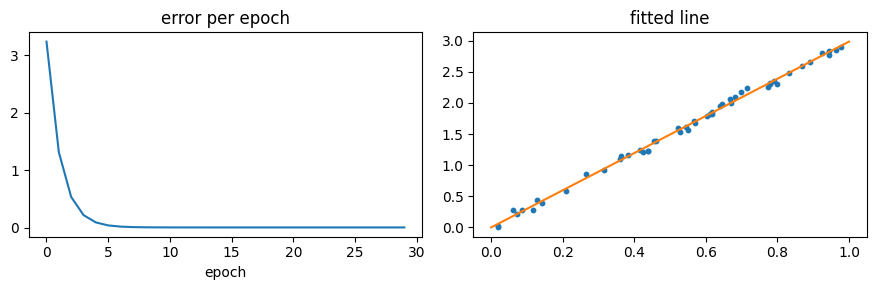

In [2]:
## 2. Demo: Unsupervised learning (k-means clustering)

K-means mengelompokkan data ke dalam k kluster tanpa pernah melihat label apa pun. Algoritma ini menyesuaikan k titik pusat (centroid) secara berulang hingga setiap titik data berada di dekat pusat terdekatnya.

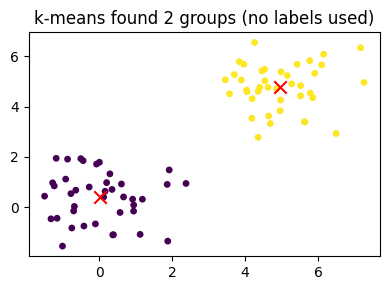

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
# data sintetis: dua kluster
group1 = np.random.randn(40, 2) + np.array([0, 0])
group2 = np.random.randn(40, 2) + np.array([5, 5])
points = np.vstack([group1, group2])

# centroid acak awal
centers = points[np.random.choice(len(points), 2, replace=False)]

for _ in range(10):
    dists = np.linalg.norm(points[:, None, :] - centers[None, :, :], axis=2)
    labels = dists.argmin(axis=1)
    centers = np.array([points[labels == k].mean(axis=0) for k in range(2)])

plt.figure(figsize=(4, 3))
plt.scatter(points[:, 0], points[:, 1], c=labels, s=15)
plt.scatter(centers[:, 0], centers[:, 1], marker='x', color='red', s=80)
plt.title('k-means menemukan 2 kelompok (tanpa label)'); plt.tight_layout(); plt.show()

### Demo 3: Prediksi non-parametrik (k-nearest neighbors)
Klasifikasi k-NN tidak memiliki bobot untuk dilatih. Algoritma ini *menyimpan seluruh dataset* dan memprediksi dengan melihat contoh tersimpan yang paling dekat, sehingga "ukuran model" bertambah seiring bertambahnya data.

In [4]:
labels_true = np.array([0] * 40 + [1] * 40)

def knn_predict(query, k=5):
    d = np.linalg.norm(points - query, axis=1)
    nearest = labels_true[np.argsort(d)[:k]]
    return np.bincount(nearest).argmax()

print('prediksi untuk (0.5, 0.5):', knn_predict(np.array([0.5, 0.5])))
print('prediksi untuk (4.5, 5.5):', knn_predict(np.array([4.5, 5.5])))

prediction for (0.5, 0.5): 0
prediction for (4.5, 5.5): 1


## Tabel ringkasan
| | Parametrik | Non-parametrik |
|---|---|---|
| **Supervised** | regresi linear, **jaringan saraf** (fokus buku ini) | k-nearest neighbors |
| **Unsupervised** | k-means (jumlah pusat tetap) | klustering hierarkis / berbasis densitas |

## Poin-poin kunci
* Supervised learning menggunakan contoh berlabel, unsupervised learning menemukan struktur tanpa label.
* Model parametrik memiliki jumlah parameter yang dapat disesuaikan bernilai tetap; model non-parametrik bertambah seiring bertambahnya data.
* Jaringan saraf adalah model parametrik supervised yang dilatih dengan alur predict -> compare -> learn.